# 7 · Verbalize a Basket

A language model reads text, so each basket becomes one line. Three decisions: **what** goes in (each item once,
full names), **in what order** (shuffled every time — a basket has no order), and **how long** (in tokens, which sets
the context length for training). Plus a fixed train/validation split.

**Done when:** `my_verbalize_basket` matches the reference on 2,000 baskets.

In [1]:
import os
import warnings

os.environ["TRANSFORMERS_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer

from thilimarketbasket.dataset import generate_dataset
from thilimarketbasket.verbalize import verbalize_basket as reference_verbalize

data = generate_dataset(n_baskets=100_000, seed=0)
baskets = data.baskets
print(f"{len(baskets):,} baskets")
print(baskets[0])

100,000 baskets
['Nandini Pure Curd 500 g', 'Chatpata Potato Chips Rs 5 pack', 'Little Lotus Batteries (AA) pack of 4']


## Write it down

Quantity is dropped (like the miner did): each item once. Format: `Basket: item; item; item` — semicolons because
names contain spaces and never a semicolon.

In [2]:
def my_verbalize_basket(items, seed=None, max_items=30):
    different = sorted(set(items))                    # each item once; sorted so a seed gives a repeatable order
    rng = np.random.default_rng(seed)
    order = rng.permutation(len(different))[:max_items]
    return "Basket: " + "; ".join(different[i] for i in order)


for seed in range(3):
    print(my_verbalize_basket(baskets[0], seed=seed))

Basket: Nandini Pure Curd 500 g; Chatpata Potato Chips Rs 5 pack; Little Lotus Batteries (AA) pack of 4
Basket: Chatpata Potato Chips Rs 5 pack; Little Lotus Batteries (AA) pack of 4; Nandini Pure Curd 500 g
Basket: Nandini Pure Curd 500 g; Chatpata Potato Chips Rs 5 pack; Little Lotus Batteries (AA) pack of 4


## Check: deterministic per seed, same item set every time, matches the reference

In [3]:
same_seed = my_verbalize_basket(baskets[0], seed=7) == my_verbalize_basket(list(reversed(baskets[0])), seed=7)
orders = {my_verbalize_basket(baskets[0], seed=s) for s in range(50)}
items_seen = {frozenset(t[len("Basket: "):].split("; ")) for t in orders}

print("a seed gives the same text whatever order the basket arrived in:", same_seed)
print(f"50 seeds gave {len(orders)} different texts, but only {len(items_seen)} different set of items")
print("matches the reference:", all(my_verbalize_basket(b, seed=1) == reference_verbalize(b, seed=1) for b in baskets[:2000]))

a seed gives the same text whatever order the basket arrived in: True
50 seeds gave 6 different texts, but only 1 different set of items
matches the reference: True


(3 items → only 3! = 6 orders possible.)

## Why shuffle?

Any fixed order is a cheap, meaningless rule the model would learn instead of the shop. E.g. alphabetical:

In [4]:
def alphabetical_rate(texts):
    later = total = 0
    for text in texts:
        items = text[len("Basket: "):].split("; ")
        for a, b in zip(items, items[1:]):
            later += b > a
            total += 1
    return later / total

sample = baskets[:5000]
fixed = ["Basket: " + "; ".join(sorted(set(b))) for b in sample]
shuffled = [my_verbalize_basket(b, seed=i) for i, b in enumerate(sample)]

print(f"sorted order:   the next item is later in the alphabet {alphabetical_rate(fixed):.0%} of the time")
print(f"shuffled order: {alphabetical_rate(shuffled):.0%}")

sorted order:   the next item is later in the alphabet 100% of the time
shuffled order: 50%


In training we reshuffle every time a basket is shown, so the model sees each set from many directions.

## How many tokens?

Tokenizer of SmolLM2-135M, the model we'll train later.

In [5]:
tokenizer = AutoTokenizer.from_pretrained("HuggingFaceTB/SmolLM2-135M")
print(f"vocabulary: {len(tokenizer):,} tokens\n")

for name in ("Onion 1 kg", "Surya Grains Toor Dal 1 kg", "Rasoi Royale Coriander Powder sachet 10 g"):
    print(f"{name}\n   {len(tokenizer.tokenize(name))} tokens: {tokenizer.tokenize(name)}\n")

vocabulary: 49,152 tokens

Onion 1 kg
   5 tokens: ['On', 'ion', 'Ġ', '1', 'Ġkg']

Surya Grains Toor Dal 1 kg
   11 tokens: ['S', 'ury', 'a', 'ĠGra', 'ins', 'ĠTo', 'or', 'ĠDal', 'Ġ', '1', 'Ġkg']

Rasoi Royale Coriander Powder sachet 10 g
   14 tokens: ['R', 'as', 'oi', 'ĠRoy', 'ale', 'ĠCor', 'iander', 'ĠPowder', 'Ġsac', 'het', 'Ġ', '1', '0', 'Ġg']



Invented brands get chopped into fragments ("S ury a") — this is what "no prior knowledge" looks like.

tokens per basket: mean 108, median 102, 95th percentile 198, 99th 250, longest 356
tokens per item:   about 11.3


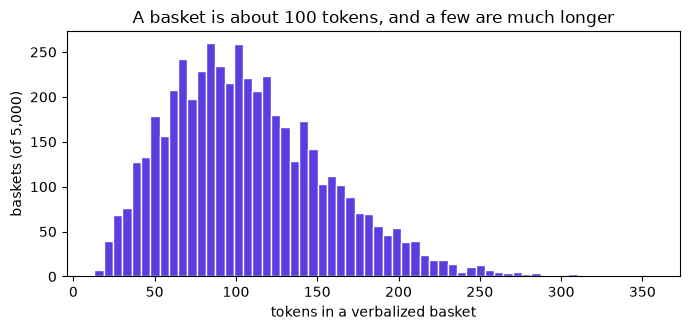

In [6]:
texts = [my_verbalize_basket(b, seed=i) for i, b in enumerate(baskets[:5000])]
lengths = np.array([len(ids) for ids in tokenizer(texts)["input_ids"]])
distinct = np.array([len(set(b)) for b in baskets[:5000]])

print(f"tokens per basket: mean {lengths.mean():.0f}, median {int(np.median(lengths))}, "
      f"95th percentile {int(np.percentile(lengths, 95))}, 99th {int(np.percentile(lengths, 99))}, longest {lengths.max()}")
print(f"tokens per item:   about {lengths.sum() / distinct.sum():.1f}")

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(lengths, bins=60, color="#5b3de0", edgecolor="white")
ax.set_xlabel("tokens in a verbalized basket")
ax.set_ylabel("baskets (of 5,000)")
ax.set_title("A basket is about 100 tokens, and a few are much longer")
plt.tight_layout()
plt.show()

## Choosing a context length

In [7]:
for cap in (128, 192, 256, 384, 512):
    print(f"context {cap:>3}: cuts {np.mean(lengths > cap):.1%} of baskets")

context 128: cuts 30.1% of baskets
context 192: cuts 6.1% of baskets
context 256: cuts 0.8% of baskets
context 384: cuts 0.0% of baskets
context 512: cuts 0.0% of baskets


256 is the smallest cap that cuts under 1% of baskets — that's the choice.

## Train / validation split (fixed seed, by basket)

In [8]:
rng = np.random.default_rng(0)
is_val = rng.random(len(baskets)) < 0.05
train = [b for b, v in zip(baskets, is_val) if not v]
val = [b for b, v in zip(baskets, is_val) if v]
print(f"{len(train):,} baskets to train on, {len(val):,} held out")

95,002 baskets to train on, 4,998 held out


Split by basket, not by item: planted patterns appear in both halves, so we test whether the model learned patterns
that are really there.

## Try it: format choices vs length

In [9]:
def length_with(separator, prefix="Basket: "):
    some = [prefix + separator.join(sorted(set(b))) for b in baskets[:2000]]
    return np.mean([len(ids) for ids in tokenizer(some)["input_ids"]])

for label, separator, prefix in (("semicolon (ours)", "; ", "Basket: "), ("comma", ", ", "Basket: "),
                                 ("pipe", " | ", "Basket: "), ("newline", "\n", "Basket:\n"),
                                 ("no prefix", "; ", "")):
    print(f"{label:18} {length_with(separator, prefix):6.1f} tokens per basket")

semicolon (ours)    107.8 tokens per basket
comma               107.8 tokens per basket


pipe                107.8 tokens per basket
newline             110.3 tokens per basket
no prefix           104.9 tokens per basket


Separators cost the same; format matters for meaning, not length.

## What I built
`my_verbalize_basket` (each item once, a fresh shuffle per seed, identical to the reference), token-length
measurements that pick a 256-token context, and the 95,002 / 4,998 train/validation split.

## Test yourself

**1. Why is each basket shuffled again every time it's shown in training?**
A basket is a set, so any fixed order is a pattern the model could learn that says nothing about shopping (like "the
next item is later in the alphabet"). Reshuffling each time means the only stable signal is which items are together.

**2. Why does "Surya Grains" get split into odd pieces like S / ury / a?**
The tokenizer was built on real text and has never seen our invented brand, so it falls back to small fragments. The
model has to learn from our baskets alone that those pieces make one item — which is the point of inventing brands.

**3. Why pick a 256-token context rather than 128 or 512?**
128 would cut about 30% of baskets, losing items (and maybe half a planted pattern). 256 cuts only 0.8%. Going to 512
cuts nothing more useful but makes every training example and step more expensive.

## My notes

Writing a basket as text is a real design choice: each item once, reshuffled every time, so the model can only learn which items are together. Surprising: an average basket is already about 108 tokens, around 11 per item, because invented brand names split into tiny pieces.